In [ ]:
# 复现训练procgcn时假设已经处理好的数据集放在 dataset/example 中
root = './dataset/example'

# 如果需要用自己的数据，按照dataset/custom_data.ipynb 先预处理数据
# root = './dataset/custom_data_proccessed'


# 读取数据集
import os
import os.path as osp
import torch
import torch_geometric as pyg
from torch_geometric.loader import DataLoader
from torch_geometric.data import InMemoryDataset, Data

# 定义数据集类
class CustomDataset(InMemoryDataset):
    def __init__(self, root, transform=None, pre_transform=None):
        super(CustomDataset, self).__init__(root, transform, pre_transform)
        self.data, self.slices = torch.load(self.processed_paths[0])

    @property
    def raw_file_names(self):
        return []  # 没有原始文件，直接生成数据

    @property
    def processed_file_names(self):
        return ['data.pt']  # 保存处理后的数据文件

    def download(self):
        # 如果需要下载数据，可以在这里实现
        pass

    def process(self):
        # 将 data_list 保存到硬盘上
        # torch.save(self.collate(pyglist), self.processed_paths[0])
        pass

# 读取数据集
dataset = CustomDataset(root=root)


In [ ]:
# 使用 DataLoader 加载数据集
import pickle
from torch.utils.data import Subset

with open('./dataset/example/train_indices.pkl','rb') as f:
    train_indices=pickle.load(f)
with open('./dataset/example/test_indices.pkl','rb') as f:
    test_indices=pickle.load(f)
train_set=Subset(dataset,train_indices)
test_set=Subset(dataset,test_indices)
train_loader = DataLoader(train_set, batch_size=32,shuffle=True)
test_loader=DataLoader(test_set, batch_size=32, shuffle=False)

In [ ]:

# 搭建ASAP神经网络
import torch
import torch.nn.functional as F
from torch.nn import Linear
from torch_geometric.nn import ASAPooling, GraphConv, JumpingKnowledge, global_mean_pool

class Net(torch.nn.Module):
    def __init__(self, num_features, num_classes, num_layers, hidden, ratio=0.8, dropout=0):
        super().__init__()
        self.conv1 = GraphConv(num_features, hidden, aggr='mean')
        self.convs = torch.nn.ModuleList()
        self.pools = torch.nn.ModuleList()
        self.convs.extend([
            GraphConv(hidden, hidden, aggr='mean')
            for i in range(num_layers - 1)
        ])
        self.pools.extend([
            ASAPooling(hidden, ratio, dropout=dropout)
            for i in range((num_layers) // 2)
        ])
        self.jump = JumpingKnowledge(mode='cat')
        self.lin1 = Linear(num_layers * hidden, hidden)
        self.lin2 = Linear(hidden, num_classes)

    def reset_parameters(self):
        self.conv1.reset_parameters()
        for conv in self.convs:
            conv.reset_parameters()
        for pool in self.pools:
            pool.reset_parameters()
        self.lin1.reset_parameters()
        self.lin2.reset_parameters()

    def forward(self, data):
        x, edge_index, batch = data.x.to_dense(), data.edge_index, data.batch #注意先把稀疏矩阵转换成密集矩阵再训练
        edge_weight = None
        x = F.relu(self.conv1(x, edge_index))
        xs = [global_mean_pool(x, batch)]
        for i, conv in enumerate(self.convs):
            x = conv(x=x, edge_index=edge_index, edge_weight=edge_weight)
            x = F.relu(x)
            xs += [global_mean_pool(x, batch)]
            if i % 2 == 0 and i < len(self.convs) - 1:
                pool = self.pools[i // 2]
                x, edge_index, edge_weight, batch, _ = pool(
                    x=x, edge_index=edge_index, edge_weight=edge_weight,
                    batch=batch)
        x = self.jump(xs)
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.lin2(x)
        return F.log_softmax(x, dim=-1)

    def __repr__(self):
        return self.__class__.__name__
      
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=Net(1834,2,4,64).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-4)

def train(epoch):
    model.train()
    loss_all = 0

    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data)
        loss = F.nll_loss(out, data.y.view(-1))
        loss.backward()
        loss_all += data.y.size(0) * float(loss)
        optimizer.step()
    return loss_all / len(train_indices)
@torch.no_grad()
def test(loader):
    model.eval()
    correct = 0
    loss_all=0

    for data in loader:
        data = data.to(device)
        pred = model(data)
        loss = F.nll_loss(pred, data.y.view(-1))
        loss_all += data.y.size(0) * float(loss)
        correct += int(pred.max(dim=1)[1].eq(data.y.view(-1)).sum())

    return loss_all / len(loader.dataset), correct / len(loader.dataset)


In [ ]:
best_test_acc = test_acc = 0
best_test_loss = float('inf')
patience = start_patience = 20
for epoch in range(1, 1000):
    train_loss = train(epoch)
    _, train_acc = test(train_loader)
    test_loss, test_acc = test(test_loader)
    if test_acc > best_test_acc:        
        best_test_acc = test_acc
        patience = start_patience
        best_epoch =  epoch
    else:
        patience -= 1
        if patience == 0:
            break
    print(f'Epoch: {epoch:03d}, Train Loss: {train_loss:.3f}, '
          f'Train Acc: {train_acc:.3f}, '
          f'Test Loss: {test_loss:.3f}, '
          f'Test Acc: {test_acc:.3f}')

print(f'The Best Epoch: {best_epoch:03d},Test Loss: {best_test_loss:.3f}, Test Acc: {best_test_acc:.3f}')
# 训练完成后，输出模型信息和内存占用信息
from torchinfo import summary
summary(model)
gpu_memory = torch.cuda.memory_allocated()
print(f"Allocated GPU Memory: {gpu_memory / (1024 ** 2)} MB")
gpu_memory = torch.cuda.max_memory_allocated()
print(f"Allocated GPU Memory: {gpu_memory / (1024 ** 2)} MB")
# 训练完成后，清除梯度,保存参数矩阵
model.zero_grad()
torch.save(model.state_dict(), './model/model_state_dict.pth')


以下代码用于加载模型并输出测试集检测结果。

In [17]:
# 搭建ASAP神经网络，加载模型参数
import torch
import torch.nn.functional as F
from torch.nn import Linear

import torch_geometric as pyg
from torch_geometric.loader import DataLoader
from torch_geometric.nn import ASAPooling, GraphConv, JumpingKnowledge, global_mean_pool

class Net(torch.nn.Module):
    def __init__(self, num_features, num_classes, num_layers, hidden, ratio=0.8, dropout=0):
        super().__init__()
        self.conv1 = GraphConv(num_features, hidden, aggr='mean')
        self.convs = torch.nn.ModuleList()
        self.pools = torch.nn.ModuleList()
        self.convs.extend([
            GraphConv(hidden, hidden, aggr='mean')
            for i in range(num_layers - 1)
        ])
        self.pools.extend([
            ASAPooling(hidden, ratio, dropout=dropout)
            for i in range((num_layers) // 2)
        ])
        self.jump = JumpingKnowledge(mode='cat')
        self.lin1 = Linear(num_layers * hidden, hidden)
        self.lin2 = Linear(hidden, num_classes)

    def reset_parameters(self):
        self.conv1.reset_parameters()
        for conv in self.convs:
            conv.reset_parameters()
        for pool in self.pools:
            pool.reset_parameters()
        self.lin1.reset_parameters()
        self.lin2.reset_parameters()

    def forward(self, data):
        x, edge_index, batch = data.x.to_dense(), data.edge_index, data.batch #注意先把稀疏矩阵转换成密集矩阵再训练
        edge_weight = None
        x = F.relu(self.conv1(x, edge_index))
        xs = [global_mean_pool(x, batch)]
        for i, conv in enumerate(self.convs):
            x = conv(x=x, edge_index=edge_index, edge_weight=edge_weight)
            x = F.relu(x)
            xs += [global_mean_pool(x, batch)]
            if i % 2 == 0 and i < len(self.convs) - 1:
                pool = self.pools[i // 2]
                x, edge_index, edge_weight, batch, _ = pool(
                    x=x, edge_index=edge_index, edge_weight=edge_weight,
                    batch=batch)
        x = self.jump(xs)
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.lin2(x)
        return F.log_softmax(x, dim=-1)

    def __repr__(self):
        return self.__class__.__name__
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=Net(1834,2,4,64).to(device)
model.load_state_dict(torch.load('./model/model_state_dict.pth'))

<All keys matched successfully>

In [18]:
# 如果需要用自己的数据，按照dataset/custom_data.ipynb 先预处理数据
# root = './dataset/custom_data_proccessed'

root = './dataset/example'

# 读取数据集
import os
import os.path as osp
import torch
import torch_geometric as pyg
from torch_geometric.loader import DataLoader
from torch_geometric.data import InMemoryDataset, Data

# 定义数据集类
class CustomDataset(InMemoryDataset):
    def __init__(self, root, transform=None, pre_transform=None):
        super(CustomDataset, self).__init__(root, transform, pre_transform)
        self.data, self.slices = torch.load(self.processed_paths[0])

    @property
    def raw_file_names(self):
        return []  # 没有原始文件，直接生成数据

    @property
    def processed_file_names(self):
        return ['data.pt']  # 保存处理后的数据文件

    def download(self):
        # 如果需要下载数据，可以在这里实现
        pass

    def process(self):
        # 将 data_list 保存到硬盘上
        # torch.save(self.collate(pyglist), self.processed_paths[0])
        pass

# 读取数据集
dataset = CustomDataset(root=root)
# 使用 DataLoader 加载数据集
import pickle
from torch.utils.data import Subset

with open('./dataset/example/test_indices.pkl','rb') as f:
    test_indices=pickle.load(f)
test_subset = Subset(dataset, test_indices)
test_loader=DataLoader(test_subset, batch_size=32,shuffle=False)

import csv
# 存储每个样本的名称和输出概率
results = []

with torch.no_grad():  # 关闭梯度计算
    for batch in test_loader:
        batch.to(device)
        # 提取 batch 中的名称属性
        names = [data['name'] for data in batch.to_data_list()]
        
        # 获取模型的输出
        outputs = model(batch)
        
        # 将 logits 转换为概率
        probabilities = F.softmax(outputs, dim=1).cpu().numpy()
        
        # 将名称和概率对应起来
        for name, prob in zip(names, probabilities):
            results.append((name, prob[1]))

# 写入 CSV 文件
with open('./temp/gcn.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(['hash', 'gcn'])  # 写入表头
    for name, prob in results:
        writer.writerow([name, prob])

d:\Program\conda\lib\site-packages\torch_geometric\utils\sparse.py:264: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:55.)
  adj = torch.sparse_csr_tensor(


In [ ]:
''''
在这个代码块加入ember的代码
输入
'dataset/train_hash.csv'训练集
'dataset/test_hash.csv'测试集

最后ember输出 'temp/ember.csv' 为测试集的结果，即test_hash的结果,两列数据 表头是['hash','label','ember']全小写
'''
import os
import csv
import ember
import lightgbm as lgb

# 固定参数设置
feature_version = 2
model_path = "dataset/ember_model.txt"  # 预训练的EMBER模型路径
input_csv = "dataset/test_hash.csv"      # 测试集标签CSV文件（第一列为PE文件名，第二列为标签）
output_csv = "temp/ember.csv"            # 输出结果文件路径
benign_folder = "dataset/Benign"         # 良性样本目录
malicious_folder = "dataset/Malicious"   # 恶意样本目录

# 检查模型文件是否存在
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Ember model {model_path} does not exist")
    
# 加载模型
lgbm_model = lgb.Booster(model_file=model_path)

# 检查输入CSV文件是否存在
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"Input CSV file {input_csv} does not exist")

results = []
# 读取CSV文件中的样本信息
with open(input_csv, "r", newline="") as csvfile:
    reader = csv.reader(csvfile)
    header = next(reader)  # 读取表头
    # 如果表头不是我们期望的，则可以考虑还原或跳过
    for row in reader:
        if len(row) < 2:
            continue  # 跳过格式不正确的行
        sample_hash, label = row[0].strip(), row[1].strip()
        file_path = None
        # 依次在良性和恶意文件夹中查找对应的PE文件
        for folder in [benign_folder, malicious_folder]:
            candidate = os.path.join(folder, sample_hash)
            if os.path.exists(candidate):
                file_path = candidate
                break
        if file_path is None:
            # 找不到文件时，记录结果
            results.append([sample_hash, label, "File Not Found"])
        else:
            try:
                with open(file_path, "rb") as f:
                    file_data = f.read()
                # 使用 ember 库进行预测
                score = ember.predict_sample(lgbm_model, file_data, feature_version)
                results.append([sample_hash, label, str(score)])
            except Exception as e:
                results.append([sample_hash, label, "Error: " + str(e)])

# 确保输出目录存在
output_dir = os.path.dirname(output_csv)
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 将结果写入输出CSV文件，表头为 ['hash', 'label', 'ember']
with open(output_csv, "w", newline="") as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(["hash", "label", "ember"])
    for row in results:
        writer.writerow(row)

print("Prediction results have been written to", output_csv)


In [1]:
# 计算两个模型输出的平均值,得到最终的预测结果
import csv

# 读取 CSV 文件并将其转换为字典
def read_csv_to_dict(file_path, key_column, value_column):
    result_dict = {}
    with open(file_path, mode='r', newline='', encoding='utf-8') as file:
        reader = csv.DictReader(file)
        for row in reader:
            key = row[key_column]
            value = float(row[value_column])  # 假设值是浮点数
            result_dict[key] = value
    return result_dict

# 计算两个字典中对应键的值的平均值
def calculate_average(dict1, dict2):
    result_dict = {}
    for key in dict1:
        if key in dict2:
            avg_value = (dict1[key] + dict2[key]) / 2
            result_dict[key] = avg_value
    return result_dict


# 读取两个模型的输出值为字典，读取原数据标签为字典
gcn_pre = read_csv_to_dict('./temp/gcn.csv', "hash", 'gcn')
ember_pre = read_csv_to_dict('./temp/ember.csv', "hash", 'ember')


# 计算平均作为预测值
average_dict = calculate_average(gcn_pre, ember_pre)
# 把最终预测值写入csv文件，画roc曲线
with open('temp/avg.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    
    # 写入表头（可选）
    writer.writerow(['hash', 'pre'])
    
    # 写入字典的键值对
    for key, value in average_dict.items():
        writer.writerow([key, value])
        
# 把最终预测结果写入csv文件
with open('result.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    
    # 写入表头（可选）
    writer.writerow(['hash', 'label'])
    
    # 写入字典的键值对
    for key, value in average_dict.items():
        writer.writerow([key, 1 if value > 0.5 else 0])

Confusion Matrix:
[[377   8]
 [  5 380]]
Accuracy: 0.9831168831168832
Precision: 0.979381443298969
Recall: 0.987012987012987
F1 Score: 0.983182406209573
AUC: 0.9994265474784955


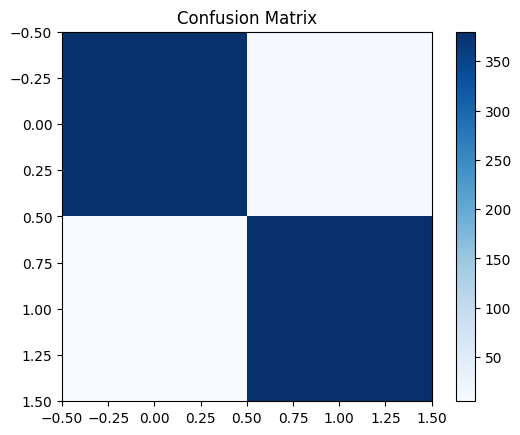

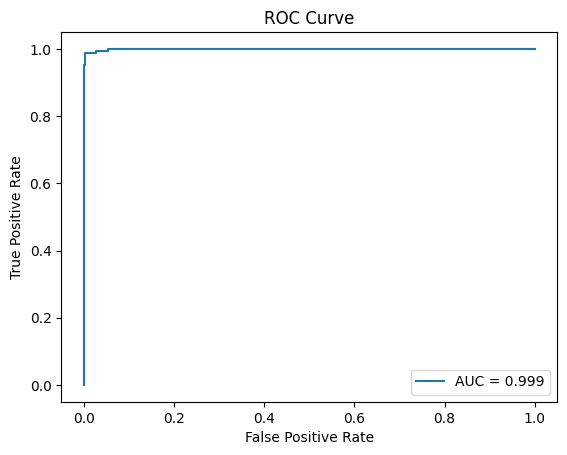

In [1]:
# 比较预测值和原始标签，计算混淆矩阵和评估指标
import sklearn
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# 比较预测值和原始标签，计算混淆矩阵和评估指标
import csv

# 读取 CSV 文件并将其转换为字典
def read_csv_to_dict(file_path, key_column, value_column):
    result_dict = {}
    with open(file_path, mode='r', newline='', encoding='utf-8') as file:
        reader = csv.DictReader(file)
        for row in reader:
            key = row[key_column]
            value = float(row[value_column])  # 假设值是浮点数
            result_dict[key] = value
    return result_dict
origin_label=read_csv_to_dict('./dataset/test_hash.csv',"hash", 'label')
pred_res=read_csv_to_dict('./temp/avg.csv','hash','pre')

# 提取标签和预测值
y_true = list(origin_label.values())
y_pred = [1 if value > 0.5 else 0 for value in pred_res.values()]
y_pred_prob = [pred_res[key] for key in pred_res]  # 模型的预测概率

# 计算混淆矩阵
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)

# 计算其他指标
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# 计算 ROC 曲线的真正率和假正率
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print(f"AUC: {roc_auc}")

# 绘制混淆矩阵
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()
plt.show()



# 绘制 ROC 曲线
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()



通过以上步骤得到了最终结果'result.csv',label列0是良性软件，1是恶意软件